# Análise Exploratória — Leonardo Pires

## Projeto Minha Casa Minha Vida

Objetivo: investigar a qualidade dos dados utilizados na previsão do valor de financiamento habitacional.

In [1]:
# Manipulação e análise de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# Manipulação de caminhos e arquivos
from pathlib import Path

In [4]:
# Localiza a base de dados na raiz do projeto
# O notebook está na pasta "notebooks", por isso usamos .parent
arquivo = Path.cwd().parent / "mcmv_financiamentos_2020_2026.zip"

# Carrega os dados diretamente do arquivo ZIP
df = pd.read_csv(
    arquivo,
    sep=";",              # Separador das colunas
    decimal=",",          # Separador decimal brasileiro
    thousands=".",        # Separador de milhares
    encoding="utf-8-sig", # Codificação do arquivo
    compression="zip",    # Leitura direta do ZIP
    low_memory=False      # Evita inferência fragmentada dos tipos
)

# Exibe a quantidade de linhas e colunas
print("Base carregada com sucesso!")
print(f"Linhas: {df.shape[0]:,}")
print(f"Colunas: {df.shape[1]}")

Base carregada com sucesso!
Linhas: 3,288,670
Colunas: 21


In [5]:
# Identifica a quantidade de valores ausentes em cada coluna
valores_ausentes = df.isnull().sum()

# Calcula o percentual de valores ausentes por coluna
percentual_ausentes = (valores_ausentes / len(df)) * 100

# Organiza os resultados em uma tabela
resumo_ausentes = pd.DataFrame({
    "Valores Ausentes": valores_ausentes,
    "Percentual (%)": percentual_ausentes.round(2)
})

# Ordena as colunas da maior para a menor quantidade de ausentes
resumo_ausentes = resumo_ausentes.sort_values(
    by="Valores Ausentes",
    ascending=False
)

# Exibe o resultado
display(resumo_ausentes)

,Valores Ausentes,Percentual (%)
bln_cotista,2846028,86.54
txt_compatibilidade_faixa_renda,91795,2.79
txt_sistema_amortizacao,40192,1.22
co_sexo,19517,0.59
vlr_subsidio_equilíbrio_ogu,11198,0.34
vlr_subsidio_equilíbrio_fgts,11198,0.34
txt_tipo_imovel,6565,0.20
cod_ibge,2,0.00
mcmv_fgts_txt_uf,2,0.00
txt_municipio,2,0.00


In [6]:
# Investiga os valores existentes na variável bln_cotista
# dropna=False inclui os valores ausentes (NaN) na contagem

df["bln_cotista"].value_counts(dropna=False)

bln_cotista
NaN    2846028
S       175891
N       139157
1        97147
0        30447
Name: count, dtype: int64

In [7]:
# Verifica o tipo de dado armazenado na coluna bln_cotista
print(df["bln_cotista"].dtype)

# Identifica os valores distintos, incluindo os ausentes
print(df["bln_cotista"].unique())

object
['N' 'S' '1' '0' nan]


In [8]:
# Extrai o ano da assinatura de cada financiamento
anos = pd.to_datetime(
    df["data_assinatura_financiamento"]
).dt.year

# Calcula o percentual de valores ausentes em bln_cotista por ano
ausentes_por_ano = (
    df["bln_cotista"]
    .isna()
    .groupby(anos)
    .mean()
    .mul(100)
    .round(2)
)

# Exibe o resultado
print(ausentes_por_ano)

data_assinatura_financiamento
2020    100.00
2021    100.00
2022    100.00
2023    100.00
2024    100.00
2025     93.42
2026      0.00
Name: bln_cotista, dtype: float64



## 1. Análise Exploratória — Qualidade dos Dados

### Visão geral
- **Registros:** 3.288.670
- **Variáveis:** 21
- **Período:** 2020 a 2026
- **Variável-alvo:** `vlr_financiamento` (sem valores ausentes).

### Valores ausentes
As principais variáveis com dados ausentes são:

| Variável | Ausentes (%) |
|---|---:|
| `bln_cotista` | 86,54% |
| `txt_compatibilidade_faixa_renda` | 2,79% |
| `txt_sistema_amortizacao` | 1,22% |
| `co_sexo` | 0,59% |

As demais variáveis apresentam menos de 0,5% de valores ausentes.

### Investigação de `bln_cotista`
Foram identificados valores `S`, `N`, `1` e `0`, indicando possível inconsistência de representação.

A ausência de dados também varia conforme o ano:

- **2020–2024:** 100% ausentes.
- **2025:** 93,42% ausentes.
- **2026:** 0% ausentes.

### Conclusão
A base apresenta boa completude na maioria das variáveis, incluindo a variável-alvo.

A principal ressalva é `bln_cotista`, devido à elevada ausência de dados, concentrada nos anos anteriores a 2026, e à possível inconsistência de representação.

**Decisão provisória:** avaliar a exclusão dessa variável na modelagem. Nenhum dado foi alterado nesta etapa.


In [9]:
# Conta quantas linhas estão completamente duplicadas
duplicados = df.duplicated().sum()

# Calcula o percentual de duplicados na base
percentual = (duplicados / len(df)) * 100

# Exibe os resultados
print(f"Registros duplicados: {duplicados:,}")
print(f"Percentual: {percentual:.2f}%")

Registros duplicados: 5,507
Percentual: 0.17%


In [10]:
# Seleciona todas as linhas que possuem outra linha idêntica
registros_duplicados = df[df.duplicated(keep=False)]

# Exibe os primeiros 10 registros para inspeção
display(registros_duplicados.head(10))

,data_referencia,cod_ibge,txt_municipio,mcmv_fgts_txt_uf,txt_regiao,data_assinatura_financiamento,qtd_uh_financiadas,vlr_financiamento,vlr_subsidio_desconto_fgts,vlr_subsidio_desconto_ogu,...,vlr_subsidio_equilíbrio_ogu,vlr_compra,vlr_renda_familiar,txt_programa_fgts,num_taxa_juros,txt_tipo_imovel,bln_cotista,txt_sistema_amortizacao,txt_compatibilidade_faixa_renda,co_sexo
116,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-23,1,99750.0,65000.0,0.0,...,0.0,215000.0,1900.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,M
132,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-07-08,1,99750.0,65000.0,0.0,...,0.0,215000.0,1900.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
134,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-07-03,1,99750.0,65000.0,0.0,...,0.0,215000.0,1950.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
147,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-25,1,99750.0,65000.0,0.0,...,0.0,215000.0,1900.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
149,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-01-16,1,112000.0,65000.0,0.0,...,0.0,240000.0,1900.0,Apoio à producao,4.5,NOVO,N,price,1.0,M
151,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-23,1,99750.0,65000.0,0.0,...,0.0,215000.0,1950.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
170,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-07-03,1,99750.0,65000.0,0.0,...,0.0,215000.0,1950.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
176,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-23,1,99750.0,65000.0,0.0,...,0.0,215000.0,1950.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F
187,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-23,1,99750.0,65000.0,0.0,...,0.0,215000.0,1900.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,M
205,24/07/2026,160030.0,MACAPÁ,AP,NORTE,2026-06-18,1,99750.0,65000.0,0.0,...,0.0,215000.0,1900.0,Apoio à producao,4.5,NOVO,N,NaN,1.0,F


In [12]:
# Seleciona somente as linhas duplicadas
duplicados = df[df.duplicated()]

# Converte a coluna de texto para data e extrai o ano
anos = pd.to_datetime(
    duplicados["data_assinatura_financiamento"],
    errors="coerce"
).dt.year

# Conta os registros duplicados por ano
duplicados_por_ano = anos.value_counts().sort_index()

# Exibe o resultado
print(duplicados_por_ano)

data_assinatura_financiamento
2020     194
2021     199
2022     272
2023     524
2024     874
2025    1822
2026    1622
Name: count, dtype: int64


In [13]:
# Extrai o ano de todos os financiamentos
anos = pd.to_datetime(
    df["data_assinatura_financiamento"],
    errors="coerce"
).dt.year

# Calcula o percentual de duplicados em cada ano
percentual_duplicados = (
    duplicados_por_ano / anos.value_counts().sort_index() * 100
).round(2)

# Exibe o resultado
print(percentual_duplicados)

data_assinatura_financiamento
2020    0.05
2021    0.06
2022    0.07
2023    0.11
2024    0.14
2025    0.27
2026    0.41
Name: count, dtype: float64



### Análise de registros duplicados

Foram identificados **5.507 registros completamente idênticos**, correspondentes a **0,17% da base**.

A proporção anual de duplicados aumentou de **0,05% em 2020** para **0,41% em 2026**.

Embora exista uma tendência de crescimento, o percentual geral permanece baixo.

**Conclusão:** sem um identificador único de contratação, não é possível determinar se os registros representam duplicações indevidas ou financiamentos distintos com características iguais.

**Decisão provisória:** manter os registros até uma avaliação adicional.


In [14]:
# Calcula as principais estatísticas dos valores de financiamento
estatisticas = df["vlr_financiamento"].describe()

# Exibe os resultados
print(estatisticas)

count    3.288670e+06
mean     1.509872e+05
std      5.704403e+04
min      0.000000e+00
25%      1.121885e+05
50%      1.400000e+05
75%      1.760000e+05
max      1.500000e+06
Name: vlr_financiamento, dtype: float64


In [15]:
# Conta os financiamentos com valor igual a zero
financiamentos_zerados = (df["vlr_financiamento"] == 0).sum()

# Calcula o percentual em relação à base
percentual_zerados = (
    financiamentos_zerados / len(df) * 100
)

# Exibe os resultados
print(f"Financiamentos zerados: {financiamentos_zerados:,}")
print(f"Percentual: {percentual_zerados:.4f}%")

Financiamentos zerados: 674
Percentual: 0.0205%


In [16]:
# Seleciona os financiamentos com valor igual a zero
df_zerados = df[df["vlr_financiamento"] == 0]

# Exibe informações relevantes desses financiamentos
display(df_zerados[[
    "data_assinatura_financiamento",
    "vlr_financiamento",
    "vlr_compra",
    "vlr_renda_familiar",
    "txt_programa_fgts",
    "txt_tipo_imovel"
]].head(10))

,data_assinatura_financiamento,vlr_financiamento,vlr_compra,vlr_renda_familiar,txt_programa_fgts,txt_tipo_imovel
315100,2026-07-20,0.0,210000.00,5772.83,Fundo Social,NaN
315109,2026-05-28,0.0,213000.00,6110.14,Fundo Social,NaN
315119,2026-05-27,0.0,350000.00,7117.17,Fundo Social,NaN
315122,2026-05-28,0.0,240000.00,8730.65,Fundo Social,NaN
315220,2026-05-28,0.0,310000.00,5986.38,Fundo Social,NaN
315221,2026-05-25,0.0,230000.00,5324.53,Fundo Social,NaN
315223,2026-06-26,0.0,286500.00,6000.00,Fundo Social,NaN
315230,2026-05-26,0.0,269335.91,8891.62,Fundo Social,NaN
315257,2026-04-27,0.0,350000.00,7300.00,Fundo Social,NaN
315268,2026-04-29,0.0,280000.00,7288.29,Fundo Social,NaN


In [43]:
# Conta os financiamentos zerados por programa
print(df_zerados["txt_programa_fgts"].value_counts())

txt_programa_fgts
Fundo Social    674
Name: count, dtype: int64


In [44]:
# Seleciona todos os registros do programa Fundo Social
fundo_social = df[df["txt_programa_fgts"] == "Fundo Social"]

# Conta os financiamentos zerados e positivos
print("Total Fundo Social:", len(fundo_social))
print("Financiamentos zerados:", (fundo_social["vlr_financiamento"] == 0).sum())
print("Financiamentos positivos:", (fundo_social["vlr_financiamento"] > 0).sum())

Total Fundo Social: 127594
Financiamentos zerados: 674
Financiamentos positivos: 126920



### Análise da variável-alvo

O valor médio dos financiamentos é de aproximadamente **R$ 150.987**, com mediana de **R$ 140.000**.

Foram identificados **674 financiamentos zerados (0,0205% da base)**, todos pertencentes ao programa Fundo Social.

Nesse programa, existem 126.920 financiamentos com valores positivos, indicando que o valor zero não é uma característica geral.

**Decisão provisória:** avaliar a exclusão dos registros zerados antes do treinamento, mantendo a base original preservada.


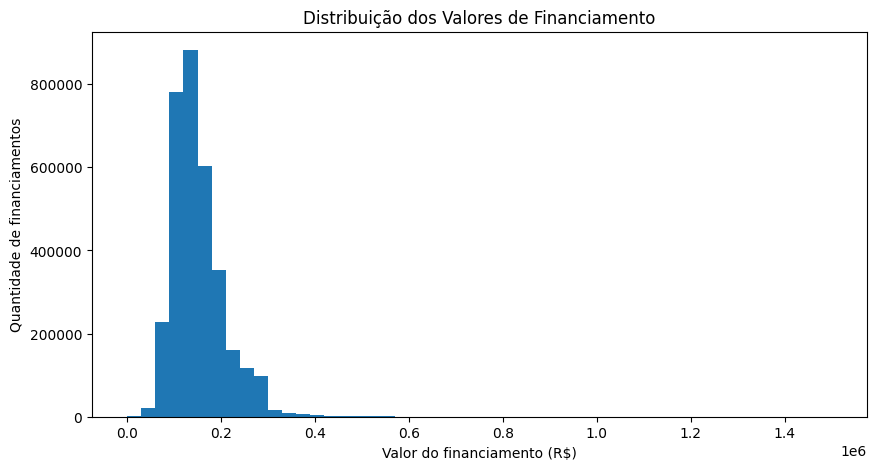

In [45]:
# Cria um histograma dos valores de financiamento
plt.figure(figsize=(10, 5))

plt.hist(df["vlr_financiamento"], bins=50)

# Adiciona título e identificação dos eixos
plt.title("Distribuição dos Valores de Financiamento")
plt.xlabel("Valor do financiamento (R$)")
plt.ylabel("Quantidade de financiamentos")

# Exibe o gráfico
plt.show()


### Distribuição dos financiamentos

O histograma mostrou que a maioria dos financiamentos está concentrada entre R$ 100 mil e R$ 200 mil.

A distribuição apresenta assimetria à direita, com poucos financiamentos de valores muito elevados.

Esses valores extremos serão considerados na preparação e avaliação do modelo.


In [46]:
# Seleciona as colunas numéricas da base
colunas_numericas = df.select_dtypes(include="number").columns

# Exibe os nomes dessas colunas
print(colunas_numericas.tolist())

['cod_ibge', 'qtd_uh_financiadas', 'vlr_financiamento', 'vlr_subsidio_desconto_fgts', 'vlr_subsidio_desconto_ogu', 'vlr_subsidio_equilíbrio_fgts', 'vlr_subsidio_equilíbrio_ogu', 'vlr_compra', 'vlr_renda_familiar', 'num_taxa_juros', 'txt_compatibilidade_faixa_renda']


In [47]:
# Calcula a correlação entre renda familiar e valor financiado
correlacao = df["vlr_renda_familiar"].corr(df["vlr_financiamento"])

# Exibe o resultado
print(f"Correlação entre renda e financiamento: {correlacao:.3f}")

Correlação entre renda e financiamento: 0.685


In [48]:
# Calcula a correlação entre o valor do imóvel e o financiamento
correlacao_compra = df["vlr_compra"].corr(df["vlr_financiamento"])

# Exibe o resultado
print(f"Correlação entre compra e financiamento: {correlacao_compra:.3f}")

Correlação entre compra e financiamento: 0.886



### Correlação com o valor do financiamento

Foram analisadas duas variáveis:

- **Renda familiar:** correlação de 0,685.
- **Valor do imóvel:** correlação de 0,886.

Ambas apresentam correlação positiva com o valor financiado, sendo a relação com o valor do imóvel mais forte.

**Conclusão:** as duas variáveis são candidatas a serem utilizadas no modelo de regressão, após avaliação do risco de vazamento de dados.


In [49]:
# Seleciona as variáveis que serão usadas para prever o financiamento
colunas = ["vlr_compra", "vlr_renda_familiar", "vlr_financiamento"]

# Cria uma cópia apenas com essas colunas
dados_modelo = df[colunas].copy()

# Remove registros com informações ausentes
dados_modelo = dados_modelo.dropna()

# Remove financiamentos com valor igual a zero
dados_modelo = dados_modelo[dados_modelo["vlr_financiamento"] > 0]

# Exibe a quantidade de registros restantes
print("Registros disponíveis:", len(dados_modelo))

Registros disponíveis: 3287995


In [50]:
from sklearn.model_selection import train_test_split

# X contém as informações usadas para fazer a previsão
X = dados_modelo[["vlr_compra", "vlr_renda_familiar"]]

# y contém o valor que queremos prever
y = dados_modelo["vlr_financiamento"]

# Divide os dados em 80% para treino e 20% para teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Mostra a quantidade de registros em cada grupo
print("Registros de treino:", len(X_treino))
print("Registros de teste:", len(X_teste))

Registros de treino: 2630396
Registros de teste: 657599


In [51]:
from sklearn.linear_model import LinearRegression

# Cria o modelo de regressão linear
modelo = LinearRegression()

# Treina o modelo com os dados de treinamento
modelo.fit(X_treino, y_treino)

# Confirma que o treinamento foi concluído
print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [52]:
from sklearn.metrics import mean_absolute_error, r2_score

# Faz previsões utilizando os dados de teste
previsoes = modelo.predict(X_teste)

# Calcula o erro médio das previsões
mae = mean_absolute_error(y_teste, previsoes)

# Calcula o R² do modelo
r2 = r2_score(y_teste, previsoes)

# Exibe os resultados
print(f"Erro médio (MAE): R$ {mae:,.2f}")
print(f"R²: {r2:.3f}")

Erro médio (MAE): R$ 16,532.14
R²: 0.791


In [53]:
# Usa a média dos financiamentos de treino como previsão
previsao_basica = [y_treino.mean()] * len(y_teste)

# Calcula o erro dessa previsão simples
mae_basico = mean_absolute_error(y_teste, previsao_basica)

# Compara os resultados
print(f"MAE básico: R$ {mae_basico:,.2f}")
print(f"MAE do modelo: R$ {mae:,.2f}")

MAE básico: R$ 41,337.20
MAE do modelo: R$ 16,532.14



### Primeiro modelo — Regressão Linear

Foi treinado um modelo de Regressão Linear utilizando duas variáveis:
- Valor do imóvel (`vlr_compra`)
- Renda familiar (`vlr_renda_familiar`)

Os dados foram divididos em 80% para treinamento e 20% para teste.

**Resultados:**
- MAE: R$ 16.532
- R²: 0,791
- MAE da previsão básica: R$ 41.337

O modelo reduziu o erro médio em aproximadamente 60% em comparação com a previsão básica.

**Conclusão:** a Regressão Linear apresentou resultados promissores, mesmo utilizando apenas duas variáveis.



### Objetivo e cuidados com o modelo

O modelo tem finalidade analítica e educacional: estimar o valor financiado utilizando informações registradas nas contratações.

Foram utilizadas a renda familiar e o valor do imóvel como variáveis preditoras.

A divisão aleatória de treino e teste avalia o desempenho em registros da mesma base, não necessariamente em contratações futuras.

O risco de vazamento de dados deve ser considerado na escolha das variáveis.


In [54]:
# Calcula as previsões nos dados de treinamento
previsoes_treino = modelo.predict(X_treino)

# Calcula o erro nos dados de treinamento
mae_treino = mean_absolute_error(y_treino, previsoes_treino)

# Compara com o erro que já calculamos nos dados de teste
print(f"MAE Treino: R$ {mae_treino:,.2f}")
print(f"MAE Teste:  R$ {mae:,.2f}")

MAE Treino: R$ 16,509.81
MAE Teste:  R$ 16,532.14



### Verificação de overfitting

Foram comparados os erros do modelo nos conjuntos de treinamento e teste.

- **MAE Treino:** R$ 16.509,81
- **MAE Teste:** R$ 16.532,14

Os resultados foram muito próximos, indicando ausência de sinais relevantes de overfitting nessa avaliação.

O modelo apresentou desempenho semelhante nos dois conjuntos.


In [55]:
# Cria uma cópia dos dados com as datas de contratação
dados_temporais = df[[
    "data_assinatura_financiamento",
    "vlr_compra",
    "vlr_renda_familiar",
    "vlr_financiamento"
]].copy()

# Converte as datas para o formato adequado
dados_temporais["data_assinatura_financiamento"] = pd.to_datetime(
    dados_temporais["data_assinatura_financiamento"]
)

# Remove registros incompletos e financiamentos zerados
dados_temporais = dados_temporais.dropna()
dados_temporais = dados_temporais[
    dados_temporais["vlr_financiamento"] > 0
]

# Separa os registros por período
treino_temporal = dados_temporais[
    dados_temporais["data_assinatura_financiamento"].dt.year < 2026
]

teste_temporal = dados_temporais[
    dados_temporais["data_assinatura_financiamento"].dt.year == 2026
]

# Exibe a quantidade de registros
print("Treino (2020–2025):", len(treino_temporal))
print("Teste (2026):", len(teste_temporal))

Treino (2020–2025): 2890028
Teste (2026): 397967


In [56]:
# Define as variáveis utilizadas na previsão
variaveis = ["vlr_compra", "vlr_renda_familiar"]

# Separa as entradas e os valores reais
X_treino_temp = treino_temporal[variaveis]
y_treino_temp = treino_temporal["vlr_financiamento"]

X_teste_temp = teste_temporal[variaveis]
y_teste_temp = teste_temporal["vlr_financiamento"]

# Cria e treina o modelo com dados de 2020 a 2025
modelo_temporal = LinearRegression()
modelo_temporal.fit(X_treino_temp, y_treino_temp)

# Faz previsões para os financiamentos de 2026
previsoes_temp = modelo_temporal.predict(X_teste_temp)

# Avalia o desempenho
mae_temporal = mean_absolute_error(y_teste_temp, previsoes_temp)
r2_temporal = r2_score(y_teste_temp, previsoes_temp)

print(f"MAE temporal: R$ {mae_temporal:,.2f}")
print(f"R² temporal: {r2_temporal:.3f}")

MAE temporal: R$ 21,842.68
R² temporal: 0.767



### Validação temporal

Foi realizada uma segunda avaliação, utilizando financiamentos de 2020 a 2025 para treinamento e de 2026 para teste.

| Métrica | Divisão aleatória | Divisão temporal |
|---|---:|---:|
| MAE | R$ 16.532 | R$ 21.843 |
| R² | 0,791 | 0,767 |

O modelo apresentou erro aproximadamente 32% maior na validação temporal.

**Conclusão:** o desempenho diminuiu ao avaliar financiamentos de um período posterior, mostrando a importância de considerar mudanças ao longo do tempo.


In [57]:
# Calcula a média dos financiamentos de treinamento
media_treino = y_treino_temp.mean()

# Usa essa média como previsão para todos os registros de 2026
previsoes_baseline = np.full(len(y_teste_temp), media_treino)

# Calcula o erro dessa previsão simples
mae_baseline_temp = mean_absolute_error(
    y_teste_temp, previsoes_baseline
)

# Compara os resultados
print(f"MAE Baseline: R$ {mae_baseline_temp:,.2f}")
print(f"MAE Regressão Linear: R$ {mae_temporal:,.2f}")

MAE Baseline: R$ 52,925.27
MAE Regressão Linear: R$ 21,842.68


In [63]:
# Extrai o ano de todos os financiamentos
anos = pd.to_datetime(
    df["data_assinatura_financiamento"],
    errors="coerce"
).dt.year

# Exibe o resultado
print(percentual_duplicados)

data_assinatura_financiamento
2020    0.05
2021    0.06
2022    0.07
2023    0.11
2024    0.14
2025    0.27
2026    0.41
Name: count, dtype: float64


In [64]:
# Faz a mesma previsão para todos os registros de 2026
previsoes_baseline = np.full(len(y_teste_temp), media_treino)

# Calcula o erro médio dessa previsão
mae_baseline_temp = mean_absolute_error(
    y_teste_temp, previsoes_baseline
)

print(f"MAE Baseline: R$ {mae_baseline_temp:,.2f}")
print(f"MAE Regressão Linear: R$ {mae_temporal:,.2f}")

MAE Baseline: R$ 52,925.27
MAE Regressão Linear: R$ 21,842.68



### Comparação com o baseline temporal

Foi utilizado um baseline que prevê sempre a média dos financiamentos do período de treinamento (2020–2025).

- MAE Baseline: R$ 52.925,27
- MAE Regressão Linear: R$ 21.842,68

A Regressão Linear reduziu o erro médio em aproximadamente 58,7% em relação ao baseline.

Esse resultado demonstra que o modelo consegue aproveitar informações sobre o valor do imóvel e a renda familiar para produzir estimativas melhores que a média histórica.


In [60]:
# Mostra os coeficientes aprendidos pelo modelo temporal
for variavel, coeficiente in zip(
    X_treino_temp.columns,
    modelo_temporal.coef_
):
    print(f"{variavel}: {coeficiente:.4f}")

# Mostra o intercepto
print(f"Intercepto: {modelo_temporal.intercept_:.2f}")

vlr_compra: 0.5783
vlr_renda_familiar: 1.6432
Intercepto: 22507.39



### Interpretação dos coeficientes

O modelo de Regressão Linear apresentou os seguintes coeficientes:

- Valor do imóvel: 0,5783
- Renda familiar: 1,6432
- Intercepto: R$ 22.507,39

Mantendo as demais variáveis constantes, um aumento de R$ 1.000 no valor do imóvel está associado a um aumento de aproximadamente R$ 578 na previsão do financiamento.

Um aumento de R$ 1.000 na renda familiar está associado a um aumento de aproximadamente R$ 1.643 na previsão.

Essas relações são estatísticas e não representam causalidade.


In [61]:
# Identifica previsões negativas
previsoes_negativas = (previsoes_temp < 0).sum()

# Identifica previsões superiores ao valor de compra
previsoes_acima_compra = (
    previsoes_temp > X_teste_temp["vlr_compra"].to_numpy()
).sum()

# Exibe os resultados
print("Previsões negativas:", previsoes_negativas)
print("Previsões acima do valor do imóvel:", previsoes_acima_compra)

Previsões negativas: 0
Previsões acima do valor do imóvel: 8


In [62]:
# Cria uma tabela com os valores reais e previstos
analise_erros = pd.DataFrame({
    "valor_real": y_teste_temp,
    "valor_previsto": previsoes_temp
})

# Calcula o erro absoluto de cada previsão
analise_erros["erro_absoluto"] = (
    analise_erros["valor_real"] -
    analise_erros["valor_previsto"]
).abs()

# Divide os financiamentos em quatro grupos
analise_erros["faixa"] = pd.qcut(
    analise_erros["valor_real"],
    q=4,
    duplicates="drop"
)

# Calcula o erro médio de cada grupo
erro_por_faixa = analise_erros.groupby(
    "faixa", observed=True
)["erro_absoluto"].mean()

print(erro_por_faixa.round(2))

faixa
(49999.999, 144000.0]     18339.00
(144000.0, 176000.0]      14315.08
(176000.0, 220365.36]     20976.56
(220365.36, 1500000.0]    33997.40
Name: erro_absoluto, dtype: float64



### Análise dos erros por faixa de financiamento

Os financiamentos de 2026 foram divididos em quatro grupos conforme o valor real financiado.

O menor erro médio ocorreu na faixa de R$ 144 mil a R$ 176 mil (MAE de R$ 14.315).

O maior erro médio ocorreu nos financiamentos acima de R$ 220 mil (MAE de R$ 33.997).

Essa análise demonstra que o desempenho do modelo varia conforme o valor do financiamento, sendo importante considerar essa limitação na interpretação dos resultados.
